# Assignment Beta, Question 2: LoRA, QLoRA, DoRA and AdaLoRA for tool calling

**Course:** Agentic AI (AI4015), FAST NUCES Karachi
**Student ID:** 23K-0064

In this notebook I fine-tune Qwen2.5-1.5B-Instruct to produce clean function calls for a customer support bot. I compare plain LoRA, QLoRA, DoRA and AdaLoRA against the base model, check whether a bigger rank helps, test merging, look at failures and finally try the model on a small e-commerce tool set.

How to run: on Colab, select a GPU runtime and run all cells. Every training run saves its results to Google Drive and is skipped next time if its results already exist, so after a disconnect I can just run everything again.

In [1]:
   !pip uninstall -y torchao

In [2]:
# Cell 1: install pinned versions and check the GPU
import sys, subprocess
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                    "transformers==5.22.2", "peft==0.21.2", "datasets==5.1.0",
                    "bitsandbytes==0.50.2", "accelerate==1.15.0"], check=True)

import torch
if torch.cuda.is_available():
    props = torch.cuda.get_device_properties(0)
    print("GPU:", props.name, "| total VRAM: %.1f GB" % (props.total_memory / 1024**3))
else:
    print("No GPU found, running on CPU")

In [3]:
# Cell 2: flags and where results go
import os
from pathlib import Path

SMOKE_TEST = False   # True = 20 train / 10 test examples, just to check the code runs
LOCAL_CPU = False    # True = Qwen2.5-0.5B in fp32 on CPU, QLoRA skipped (bitsandbytes needs a GPU)
# I flip these with environment variables when I test locally, so the saved notebook keeps the real settings
SMOKE_TEST = os.environ.get("Q2_SMOKE", str(int(SMOKE_TEST))) == "1"
LOCAL_CPU = os.environ.get("Q2_LOCAL_CPU", str(int(LOCAL_CPU))) == "1"

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    BASE_DIR = Path("/content/drive/MyDrive/Assignment_Beta_Q2")
else:
    BASE_DIR = Path("./results")
# smoke test results go to a separate folder so they never get "resumed" into the real run
RESULTS_DIR = BASE_DIR / "smoke_test" if SMOKE_TEST else BASE_DIR
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
print("SMOKE_TEST =", SMOKE_TEST, "| LOCAL_CPU =", LOCAL_CPU, "| results in", RESULTS_DIR.resolve())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
SMOKE_TEST = False | LOCAL_CPU = False | results in /content/drive/MyDrive/Assignment_Beta_Q2


In [4]:
import json, re, time, gc, math, random, shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import transformers, peft, datasets
from datasets import load_dataset
from transformers import (AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig,
                          TrainingArguments, Trainer, TrainerCallback, set_seed)
from peft import (LoraConfig, AdaLoraConfig, PeftModel, get_peft_model,
                  prepare_model_for_kbit_training)

SEED = 42
set_seed(SEED)
random.seed(SEED)
np.random.seed(SEED)

DEVICE = "cuda" if (torch.cuda.is_available() and not LOCAL_CPU) else "cpu"
MODEL_ID = "Qwen/Qwen2.5-1.5B-Instruct"
if LOCAL_CPU:
    # a slow internet connection can swap in a tiny test model here, only for checking the code
    MODEL_ID = os.environ.get("Q2_LOCAL_MODEL", "Qwen/Qwen2.5-0.5B-Instruct")
print("torch", torch.__version__, "| transformers", transformers.__version__,
      "| peft", peft.__version__, "| datasets", datasets.__version__)
print("device:", DEVICE, "| model:", MODEL_ID)

torch 2.14.1+cu130 | transformers 5.22.2 | peft 0.21.2 | datasets 5.1.0
device: cuda | model: Qwen/Qwen2.5-1.5B-Instruct


## Section 1: Theory

### (a) Trainable parameters for a 4096 x 4096 layer with a rank 16 LoRA adapter

LoRA keeps W0 frozen and learns the update as a product of two thin matrices, so the layer computes h = W0 x + (alpha/r) B A x.

- A has shape r x d_in = 16 x 4096 = 65,536 parameters
- B has shape d_out x r = 4096 x 16 = 65,536 parameters
- Total trainable = r (d_in + d_out) = 16 x (4096 + 4096) = **131,072**

### (b) As a percentage of the original layer

The frozen layer has 4096 x 4096 = 16,777,216 parameters.

131,072 / 16,777,216 = 0.0078125, so the adapter is **0.78%** of the layer (exactly 2r/d = 32/4096). In other words the update matrix BA is still 4096 x 4096, but it costs less than 1% of the parameters to describe.

The small calculation below checks both numbers.

In [5]:
d_in, d_out, r = 4096, 4096, 16
lora_params = r * d_in + d_out * r
layer_params = d_in * d_out
print("A:", r * d_in, "| B:", d_out * r, "| total LoRA params:", lora_params)
print("layer params:", layer_params)
print("percentage: %.4f%%" % (100 * lora_params / layer_params))

# same thing counted by torch, to be sure I didn't mess up the shapes
A = torch.nn.Linear(d_in, r, bias=False)
B = torch.nn.Linear(r, d_out, bias=False)
print("counted by torch:", sum(p.numel() for p in A.parameters()) + sum(p.numel() for p in B.parameters()))
del A, B

A: 65536 | B: 65536 | total LoRA params: 131072
layer params: 16777216
percentage: 0.7812%
counted by torch: 131072


### (c) Why B starts at zero and A starts random

The update is delta W = B A. If B = 0 then delta W = 0 at step 0, so the fine-tuned model starts out **exactly** as the pretrained model. Training begins from a model that already works, and the adapter only adds a change once the data asks for it.

A still has to be random, because of how the gradients flow. With h = W0 x + B A x:

- dL/dB = (dL/dh) (A x)^T. This is non-zero because A x is non-zero, so B starts learning on the very first step.
- dL/dA = B^T (dL/dh) (x)^T. This is zero on step 1 because B = 0, but once B has moved, A starts getting gradient too.

If both were zero, both gradients would be zero forever and nothing would train. That is why one of them has to be random.

**If both were random:** on the first forward pass delta W = B A would be a random 4096 x 4096 matrix (scaled by alpha/r) added on top of the pretrained weights in every adapted layer. The model's outputs would be damaged before training even starts, the first loss would be higher than the base model's, and the first steps would be spent undoing that noise instead of learning the task. With a high learning rate this can also produce large, unstable early updates. Starting from B = 0 avoids all of this.

### (d) What each method fixes that plain LoRA doesn't

**QLoRA** (Dettmers et al., 2023, arXiv 2305.14314). Plain LoRA cuts the trainable parameters, but the frozen base model still sits in GPU memory in 16 bit, and for big models that is the actual limit (a 65B model needs about 130 GB just for weights). QLoRA stores the frozen base in 4 bit and trains a LoRA adapter on top, while computing in 16 bit.
- *NF4 (4-bit NormalFloat):* pretrained weights are roughly normally distributed, so NF4 places its 16 levels at the quantiles of a normal distribution instead of spacing them evenly. Each level is used about equally often, so less information is lost than with plain int4.
- *Double quantization:* every block of 64 weights has its own fp32 scale constant. QLoRA quantizes these constants again (to 8 bit), saving about 0.37 bits per parameter.
- *Paged optimizers:* gradient checkpointing causes short memory spikes. Paged optimizers keep optimizer states in NVIDIA unified memory, so they get moved to CPU RAM during a spike instead of crashing with out of memory.

**DoRA** (Liu et al., 2024, arXiv 2402.09353). DoRA writes every weight as W = m * V / ||V||_c, where m is a magnitude vector (one value per column) and V / ||V||_c is a unit-length direction. The magnitude m is trained directly and LoRA is applied only to the direction V. The authors found that in plain LoRA the magnitude and direction changes are tied together (they grow together), while full fine-tuning can make large direction changes with small magnitude changes and vice versa. Splitting them lets DoRA learn more like full fine-tuning, and the gain is biggest at low ranks. The cost is extra compute for the column norm, so unmerged DoRA is slower than LoRA.

**AdaLoRA** (Zhang et al., 2023, arXiv 2303.10512). Plain LoRA gives every adapted matrix the same rank r, even though some layers and matrices matter much more for a task than others. AdaLoRA writes the update in SVD form, delta W = P Lambda Q, and gives each singular value (each "triplet") an importance score. The score is based on sensitivity, |weight x gradient|, smoothed over steps and multiplied by an uncertainty term. During training it keeps pruning the least important singular values, so the total rank budget slowly shrinks from init_r to target_r and moves to the matrices that need it. A regularizer keeps P and Q close to orthogonal so the SVD form stays meaningful.

The original LoRA paper is Hu et al., 2021, arXiv 2106.09685.

## Section 2: Data

I use `glaiveai/glaive-function-calling-v2`. Each row has a `system` text with the function definitions, and a `chat` text with USER / ASSISTANT / FUNCTION RESPONSE turns. I keep only the conversations where the **first** assistant turn is a `<functioncall>`, so the model has to call a tool straight from the user's first message.

Input = system prompt (function definitions) + the first USER message. Target = only the call, as clean JSON: `{"name": ..., "arguments": {...}}`.

In glaive the arguments come as a string inside single quotes, like `"arguments": '{"a": 1}'`, which is not valid JSON. I parse that string into a real dict and drop the rows where it fails.

I also add one sentence to every system prompt saying "reply with only a JSON object". I use the exact same prompt for the base model and for every fine-tuned model, so the base row is a fair "before" picture.

In [6]:
raw = load_dataset("glaiveai/glaive-function-calling-v2", split="train")
print("raw rows:", len(raw))

TURN_RE = re.compile(r"(USER|ASSISTANT|FUNCTION RESPONSE):\s?")
decoder = json.JSONDecoder()

def split_turns(chat):
    parts = TURN_RE.split(chat)
    return [(parts[i], parts[i + 1].replace("<|endoftext|>", "").strip())
            for i in range(1, len(parts) - 1, 2)]

def parse_functions(system):
    # the function definitions are pretty-printed JSON objects one after another
    text = system.split("Use them if required -", 1)[-1]
    funcs, i = [], 0
    while True:
        j = text.find("{", i)
        if j == -1:
            break
        try:
            obj, i = decoder.raw_decode(text, j)
        except ValueError:
            break
        funcs.append(obj)
    return funcs

def parse_glaive_call(text):
    body = text.split("<functioncall>", 1)[1].strip()
    m = re.match(r'^\{\s*"name"\s*:\s*"([^"]+)"\s*,\s*"arguments"\s*:\s*\'(.*)\'\s*\}$', body, re.S)
    if m:
        name, args = m.group(1), json.loads(m.group(2))
    else:
        obj = json.loads(body)  # a few rows already have a proper dict
        name, args = obj["name"], obj["arguments"]
        if isinstance(args, str):
            args = json.loads(args)
    if not isinstance(args, dict):
        raise ValueError("arguments is not a dict")
    return {"name": name, "arguments": args}

candidates, dropped = [], 0
for row in raw:
    turns = split_turns(row["chat"])
    if len(turns) < 2 or turns[0][0] != "USER" or turns[1][0] != "ASSISTANT":
        continue
    if not turns[1][1].startswith("<functioncall>"):
        continue
    try:
        call = parse_glaive_call(turns[1][1])
    except Exception:
        dropped += 1
        continue
    funcs = parse_functions(row["system"])
    candidates.append({
        "system": row["system"].replace("SYSTEM:", "", 1).strip(),
        "user": turns[0][1],
        "call": call,
        "func_names": [f.get("name") for f in funcs if isinstance(f, dict)],
    })

n_fc = len(candidates) + dropped
print(f"rows whose first assistant turn is a functioncall: {n_fc}")
print(f"dropped because arguments would not parse: {dropped} ({100 * dropped / n_fc:.2f}%)")
print(f"clean examples left: {len(candidates)}")

raw rows: 112960
rows whose first assistant turn is a functioncall: 37765
dropped because arguments would not parse: 10 (0.03%)
clean examples left: 37755


In [7]:
rng = random.Random(SEED)
slice_2000 = rng.sample(candidates, 2000)
train_data, test_data = slice_2000[:1800], slice_2000[1800:]
if SMOKE_TEST:
    train_data, test_data = train_data[:20], test_data[:10]
print("train:", len(train_data), "| test:", len(test_data))

with open(RESULTS_DIR / "test_set.json", "w") as f:
    json.dump(test_data, f, indent=1)

ex = train_data[0]
print("\nExample user message:", ex["user"])
print("Example target:", json.dumps(ex["call"]))

train: 1800 | test: 200

Example user message: Hi, I need to convert 100 USD to EUR. Can you help me with that?
Example target: {"name": "convert_currency", "arguments": {"from": "USD", "to": "EUR", "amount": 100}}


### Chat template, label masking and truncation

I use Qwen's own chat template. The loss is only computed on the answer tokens (the JSON plus `<|im_end|>`); every prompt token gets label -100. Max length is 1024 tokens.

In [8]:
tok = AutoTokenizer.from_pretrained(MODEL_ID)
if tok.pad_token is None:
    tok.pad_token = tok.eos_token
MAX_LEN = 1024
INSTRUCTION = ('If one of these functions fits the request, reply with only a JSON object of the form '
               '{"name": "<function name>", "arguments": {<arguments>}} and no other text.')

def prompt_text(ex):
    msgs = [{"role": "system", "content": ex["system"] + "\n\n" + INSTRUCTION},
            {"role": "user", "content": ex["user"]}]
    return tok.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True)

def target_text(ex):
    return json.dumps(ex["call"], ensure_ascii=False)

def encode(ex):
    p_ids = tok(prompt_text(ex), add_special_tokens=False)["input_ids"]
    a_ids = tok(target_text(ex) + "<|im_end|>", add_special_tokens=False)["input_ids"]
    ids = p_ids + a_ids
    labels = [-100] * len(p_ids) + a_ids
    truncated = len(ids) > MAX_LEN
    return {"input_ids": ids[:MAX_LEN], "labels": labels[:MAX_LEN]}, truncated

train_enc, n_trunc = [], 0
for ex in train_data:
    e, t = encode(ex)
    train_enc.append(e)
    n_trunc += t
lengths = [len(e["input_ids"]) for e in train_enc]
print(f"truncated at {MAX_LEN} tokens: {n_trunc} of {len(train_enc)}")
print(f"train lengths: mean {np.mean(lengths):.0f}, max {max(lengths)}")

# check the masking on one example: decode only the tokens that have a label
e = train_enc[0]
print("loss is computed on:", repr(tok.decode([t for t, l in zip(e["input_ids"], e["labels"]) if l != -100])))

def collate(batch):
    n = max(len(b["input_ids"]) for b in batch)
    pad = tok.pad_token_id
    return {
        "input_ids": torch.tensor([b["input_ids"] + [pad] * (n - len(b["input_ids"])) for b in batch]),
        "attention_mask": torch.tensor([[1] * len(b["input_ids"]) + [0] * (n - len(b["input_ids"])) for b in batch]),
        "labels": torch.tensor([b["labels"] + [-100] * (n - len(b["labels"])) for b in batch]),
    }

truncated at 1024 tokens: 0 of 1800
train lengths: mean 265, max 600
loss is computed on: '{"name": "convert_currency", "arguments": {"from": "USD", "to": "EUR", "amount": 100}}<|im_end|>'


## Section 2: Shared training config

Everything below is the same for every run. Only the adaptation method changes. All 16-bit runs use **fp16** (with mixed precision, so the LoRA weights themselves stay in fp32), so every run uses the same precision on the Colab GPU runtime. To keep memory low I use gradient checkpointing and a small per-device batch with gradient accumulation (effective batch 16).

The one difference I can't avoid: QLoRA uses `paged_adamw_8bit` because paged optimizers are part of what QLoRA is. The others use normal AdamW.

In [9]:
CONFIG = {
    "base_model": MODEL_ID,
    "seed": SEED,
    "epochs": 2,
    "learning_rate": 2e-4,
    "lr_scheduler": "cosine",
    "warmup_ratio": 0.05,
    "per_device_batch_size": 4,
    "grad_accum_steps": 4,
    "max_length": MAX_LEN,
    "lora_r": 8,
    "lora_alpha": 16,
    "lora_dropout": 0.05,
    "target_modules": ["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"],
    "precision": "fp32 (CPU smoke test)" if LOCAL_CPU else "fp16 mixed precision",
    "gradient_checkpointing": True,
    "optimizer": "adamw_torch (qlora: paged_adamw_8bit)",
    "adalora_init_r": 12,
    "adalora_target_r": 8,
    "eval_max_new_tokens": 256,
    "eval_batch_size": 4 if DEVICE == "cpu" else 16,
}
STEPS_PER_EPOCH = math.ceil(math.ceil(len(train_enc) / CONFIG["per_device_batch_size"]) / CONFIG["grad_accum_steps"])
TOTAL_STEPS = STEPS_PER_EPOCH * CONFIG["epochs"]
CONFIG["total_optimizer_steps"] = TOTAL_STEPS
print(json.dumps(CONFIG, indent=2))
with open(RESULTS_DIR / "config.json", "w") as f:
    json.dump(CONFIG, f, indent=2)

{
  "base_model": "Qwen/Qwen2.5-1.5B-Instruct",
  "seed": 42,
  "epochs": 2,
  "learning_rate": 0.0002,
  "lr_scheduler": "cosine",
  "warmup_ratio": 0.05,
  "per_device_batch_size": 4,
  "grad_accum_steps": 4,
  "max_length": 1024,
  "lora_r": 8,
  "lora_alpha": 16,
  "lora_dropout": 0.05,
  "target_modules": [
    "q_proj",
    "k_proj",
    "v_proj",
    "o_proj",
    "gate_proj",
    "up_proj",
    "down_proj"
  ],
  "precision": "fp16 mixed precision",
  "gradient_checkpointing": true,
  "optimizer": "adamw_torch (qlora: paged_adamw_8bit)",
  "adalora_init_r": 12,
  "adalora_target_r": 8,
  "eval_max_new_tokens": 256,
  "eval_batch_size": 16,
  "total_optimizer_steps": 226
}


### Helpers: loading, training, generation and scoring

In [10]:
import warnings
# When an AdaLoRA adapter is reloaded, peft warns that its rank_pattern keys "did not match".
# I checked this: the pruned ranks still load with the same shapes and values as the saved file,
# so the warning is harmless and I hide it.
warnings.filterwarnings("ignore", message="The following rank_pattern keys did not match")

def free_memory():
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

def load_base(quant4=False):
    if LOCAL_CPU:
        return AutoModelForCausalLM.from_pretrained(MODEL_ID, dtype=torch.float32)
    if quant4:
        bnb = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4",
                                 bnb_4bit_use_double_quant=True, bnb_4bit_compute_dtype=torch.float16)
        return AutoModelForCausalLM.from_pretrained(MODEL_ID, quantization_config=bnb, device_map={"": 0})
    return AutoModelForCausalLM.from_pretrained(MODEL_ID, dtype=torch.float16, device_map={"": 0})

def make_peft_config(method, r):
    common = dict(lora_alpha=2 * r, lora_dropout=CONFIG["lora_dropout"],
                  target_modules=CONFIG["target_modules"], task_type="CAUSAL_LM")
    if method in ("lora", "qlora"):
        return LoraConfig(r=r, **common)
    if method == "dora":
        return LoraConfig(r=r, use_dora=True, **common)
    if method == "adalora":
        # init_r = 1.5 x target, so r=8 gives the required 12 -> 8
        return AdaLoraConfig(init_r=int(1.5 * r), target_r=r, total_step=TOTAL_STEPS,
                             tinit=int(0.1 * TOTAL_STEPS), tfinal=int(0.2 * TOTAL_STEPS),
                             deltaT=max(1, TOTAL_STEPS // 20), **common)
    raise ValueError(method)

class AdaLoraCallback(TrainerCallback):
    # AdaLoRA needs update_and_allocate() after every optimizer step, while the grads still exist.
    # The HF Trainer does not do this by itself.
    def __init__(self, model):
        self.model = model
    def on_optimizer_step(self, args, state, control, **kwargs):
        # with fp16 the grad scaler sometimes skips a step because of inf grads;
        # those grads would poison the importance scores, so I skip them too
        for n, p in self.model.named_parameters():
            if "lora_" in n and p.grad is not None and not torch.isfinite(p.grad).all():
                return
        self.model.base_model.update_and_allocate(state.global_step)

def run_dir(name):
    d = RESULTS_DIR / "runs" / name
    d.mkdir(parents=True, exist_ok=True)
    return d

def train_run(name, method, r):
    d = run_dir(name)
    if (d / "train_metrics.json").exists():
        print(f"[{name}] already trained, loading saved metrics")
        return json.load(open(d / "train_metrics.json"))
    if method == "qlora" and LOCAL_CPU:
        print(f"[{name}] skipped: QLoRA needs bitsandbytes on a GPU")
        return None

    set_seed(SEED)
    free_memory()
    model = load_base(quant4=(method == "qlora"))
    if method == "qlora":
        model = prepare_model_for_kbit_training(model, use_gradient_checkpointing=True,
                                                gradient_checkpointing_kwargs={"use_reentrant": False})
    model = get_peft_model(model, make_peft_config(method, r))
    # fp16 mixed precision needs the trainable weights in fp32
    for p in model.parameters():
        if p.requires_grad and p.dtype != torch.float32:
            p.data = p.data.float()
    trainable, total = model.get_nb_trainable_parameters()
    print(f"[{name}] trainable {trainable:,} of {total:,} ({100 * trainable / total:.3f}%)")

    args = TrainingArguments(
        output_dir=str(d / "tmp"),
        per_device_train_batch_size=CONFIG["per_device_batch_size"],
        gradient_accumulation_steps=CONFIG["grad_accum_steps"],
        num_train_epochs=CONFIG["epochs"],
        learning_rate=CONFIG["learning_rate"],
        lr_scheduler_type=CONFIG["lr_scheduler"],
        warmup_steps=max(1, round(CONFIG["warmup_ratio"] * TOTAL_STEPS)),
        fp16=not LOCAL_CPU,
        use_cpu=LOCAL_CPU,
        gradient_checkpointing=True,
        gradient_checkpointing_kwargs={"use_reentrant": False},
        optim="paged_adamw_8bit" if method == "qlora" else "adamw_torch",
        logging_steps=1 if SMOKE_TEST else 10,
        save_strategy="no",
        report_to="none",
        seed=SEED,
        data_seed=SEED,
        remove_unused_columns=False,
        dataloader_num_workers=0,
    )
    callbacks = [AdaLoraCallback(model)] if method == "adalora" else []
    trainer = Trainer(model=model, args=args, train_dataset=train_enc,
                      data_collator=collate, callbacks=callbacks)

    if torch.cuda.is_available():
        torch.cuda.reset_peak_memory_stats()
    t0 = time.time()
    trainer.train()
    minutes = (time.time() - t0) / 60
    peak_gb = torch.cuda.max_memory_allocated() / 1024**3 if torch.cuda.is_available() else None

    model.save_pretrained(str(d / "adapter"))
    losses = [h["loss"] for h in trainer.state.log_history if "loss" in h]
    metrics = {
        "name": name, "method": method, "rank": r,
        "trainable_params": int(trainable), "total_params": int(total),
        "trainable_pct": 100 * trainable / total,
        "peak_mem_gb": peak_gb, "train_minutes": minutes,
        "optimizer_steps": trainer.state.global_step, "planned_steps": TOTAL_STEPS,
        "final_loss": losses[-1] if losses else None, "loss_history": losses,
        "truncated_examples": n_trunc,
    }
    if method == "adalora":
        rank_pattern = model.peft_config["default"].rank_pattern or {}
        metrics["adalora_final_ranks"] = {k: int(sum(v)) for k, v in rank_pattern.items()}
    with open(d / "train_metrics.json", "w") as f:
        json.dump(metrics, f, indent=1)
    shutil.rmtree(d / "tmp", ignore_errors=True)
    print(f"[{name}] done in {minutes:.1f} min, peak memory {peak_gb} GB, final loss {metrics['final_loss']}")
    del trainer, model
    free_memory()
    return metrics

def load_trained(name, method):
    model = load_base(quant4=(method == "qlora"))
    model = PeftModel.from_pretrained(model, str(run_dir(name) / "adapter"))
    return model

In [11]:
@torch.no_grad()
def generate_all(model, examples, batch_size=None, prompt_fn=prompt_text):
    batch_size = batch_size or CONFIG["eval_batch_size"]
    model.eval()
    model.config.use_cache = True
    tok.padding_side = "left"
    prompts = [prompt_fn(ex) for ex in examples]
    # sort by length so batches have less padding, then put outputs back in order
    order = sorted(range(len(prompts)), key=lambda i: len(prompts[i]))
    outputs, n_new = [None] * len(prompts), 0
    eos_ids = {tok.convert_tokens_to_ids("<|im_end|>"), tok.eos_token_id, tok.pad_token_id}
    dev = next(model.parameters()).device
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    t0 = time.time()
    for s in range(0, len(order), batch_size):
        idx = order[s:s + batch_size]
        enc = tok([prompts[i] for i in idx], return_tensors="pt", padding=True, add_special_tokens=False).to(dev)
        gen = model.generate(**enc, max_new_tokens=CONFIG["eval_max_new_tokens"], do_sample=False,
                             temperature=None, top_p=None, top_k=None, pad_token_id=tok.pad_token_id)
        for i, row in zip(idx, gen[:, enc["input_ids"].shape[1]:].tolist()):
            # count generated tokens up to and including the first stop token
            k = next((j for j, t in enumerate(row) if t in eos_ids), len(row) - 1)
            n_new += k + 1
            outputs[i] = tok.decode(row[:k + 1], skip_special_tokens=True)
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    elapsed = time.time() - t0
    return outputs, n_new / elapsed

def find_json_object(text):
    # first {...} in the text that parses as a JSON object, plus whatever text is around it
    i = text.find("{")
    while i != -1:
        try:
            obj, end = decoder.raw_decode(text, i)
            if isinstance(obj, dict):
                return obj, (text[:i] + text[end:]).strip()
        except ValueError:
            pass
        i = text.find("{", i + 1)
    return None, text.strip()

def score_one(ex, out):
    try:
        json.loads(out.strip())   # only whitespace is stripped, extra text makes it fail
        strict_ok = True
    except ValueError:
        strict_ok = False
    obj, extra = find_json_object(out)
    name = obj.get("name") if obj else None
    args = obj.get("arguments") if obj else None
    if isinstance(args, str):
        try:
            args = json.loads(args)
        except ValueError:
            pass
    tool_ok = name == ex["call"]["name"]
    return {
        "json_valid": strict_ok,
        "tool_correct": tool_ok,
        "full_match": tool_ok and args == ex["call"]["arguments"],
        "hallucinated_name": name is not None and name not in ex["func_names"],
        "extra_text": obj is not None and extra != "",
        "no_call": name is None,
        "pred_name": name, "pred_args": args,
    }

def summarize(scores):
    n = len(scores)
    s = {"n_test": n}
    for k in ["json_valid", "tool_correct", "full_match", "hallucinated_name", "extra_text", "no_call"]:
        s[k] = int(sum(x[k] for x in scores))
        s[k + "_pct"] = 100 * s[k] / n
    return s

def eval_run(name, method, model=None, examples=None):
    examples = examples or test_data
    d = run_dir(name)
    if (d / "eval_metrics.json").exists():
        print(f"[{name}] already evaluated, loading saved metrics")
        return json.load(open(d / "eval_metrics.json"))
    if method == "qlora" and LOCAL_CPU:
        return None
    own_model = model is None
    if own_model:
        free_memory()
        model = load_base() if method == "base" else load_trained(name, method)
    outs, tps = generate_all(model, examples)
    scores = [score_one(ex, o) for ex, o in zip(examples, outs)]
    metrics = summarize(scores)
    metrics["tokens_per_sec"] = tps
    with open(d / "predictions.jsonl", "w") as f:
        for ex, o, sc in zip(examples, outs, scores):
            f.write(json.dumps({"user": ex["user"], "gold": ex["call"], "func_names": ex["func_names"],
                                "output": o, **sc}) + "\n")
    with open(d / "eval_metrics.json", "w") as f:
        json.dump(metrics, f, indent=1)
    print(f"[{name}] json valid {metrics['json_valid']}/{metrics['n_test']}, tool acc {metrics['tool_correct_pct']:.1f}%, "
          f"full match {metrics['full_match_pct']:.1f}%, {tps:.1f} tok/s")
    if own_model:
        del model
        free_memory()
    return metrics

## Section 2: The five runs

Row 0 is the base model with no fine-tuning. Rows 1 to 4 are the four methods at r = 8 (AdaLoRA starts at 12 and is pruned down to 8).

In [12]:
RUNS = [("base", "base", 0), ("lora_r8", "lora", 8), ("qlora_r8", "qlora", 8),
        ("dora_r8", "dora", 8), ("adalora_r8", "adalora", 8)]
all_train, all_eval = {}, {}
for name, method, r in RUNS:
    print("=" * 20, name)
    if method != "base":
        all_train[name] = train_run(name, method, r)
    all_eval[name] = eval_run(name, method)

==================== base
[base] already evaluated, loading saved metrics
==================== lora_r8
[lora_r8] already trained, loading saved metrics
[lora_r8] already evaluated, loading saved metrics
==================== qlora_r8


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

[qlora_r8] trainable 9,232,384 of 1,552,946,688 (0.595%)


Step,Training Loss
10,0.009874
20,0.011171
30,0.005896
40,0.011057
50,0.010211
60,0.011532
70,0.007172
80,0.007120
90,0.009241
100,0.006298


[qlora_r8] done in 9.7 min, peak memory 6.526503562927246 GB, final loss 0.001588241197168827


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

... (9 outputs left out)

Step,Training Loss
10,6.333614
20,5.398813
30,4.168470
40,3.012182
50,2.361076
60,1.864587
70,1.475863
80,1.168159
90,0.921821
100,0.721853


[adalora_r8] done in 12.7 min, peak memory 8.462636947631836 GB, final loss 0.5032137870788574


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

[adalora_r8] json valid 200/200, tool acc 100.0%, full match 94.5%, 104.7 tok/s


In [13]:
def results_row(name, method, r):
    t, e = all_train.get(name), all_eval.get(name)
    if e is None:
        return None
    return {
        "run": name, "method": method, "rank": r if r else "-",
        "trainable_params": t["trainable_params"] if t else 0,
        "trainable_%": round(t["trainable_pct"], 3) if t else 0.0,
        "peak_mem_GB": round(t["peak_mem_gb"], 2) if t and t["peak_mem_gb"] else None,
        "train_min": round(t["train_minutes"], 1) if t else None,
        "json_valid": f"{e['json_valid']}/{e['n_test']}",
        "json_valid_%": round(e["json_valid_pct"], 1),
        "tool_acc_%": round(e["tool_correct_pct"], 1),
        "full_match_%": round(e["full_match_pct"], 1),
        "tok_per_s": round(e["tokens_per_sec"], 1),
        "hallucinated_names": e["hallucinated_name"],
        "extra_text": e["extra_text"],
        "no_call": e["no_call"],
    }

results = pd.DataFrame([x for x in (results_row(*run) for run in RUNS) if x])
results.to_csv(RESULTS_DIR / "results_section2.csv", index=False)
results

,run,method,rank,trainable_params,trainable_%,peak_mem_GB,train_min,json_valid,json_valid_%,tool_acc_%,full_match_%,tok_per_s,hallucinated_names,extra_text,no_call
0,base,base,-,0,0.000,NaN,NaN,200/200,100.0,100.0,94.5,225.7,0,0,0
1,lora_r8,lora,8,9232384,0.595,7.32,7.3,200/200,100.0,100.0,94.5,109.2,0,0,0
2,qlora_r8,qlora,8,9232384,0.595,6.53,9.7,200/200,100.0,100.0,94.5,81.0,0,0,0
3,dora_r8,dora,8,9877504,0.636,8.20,13.0,200/200,100.0,100.0,94.5,58.8,0,0,0
4,adalora_r8,adalora,8,13851124,0.889,8.46,12.7,200/200,100.0,100.0,94.5,104.7,0,0,0


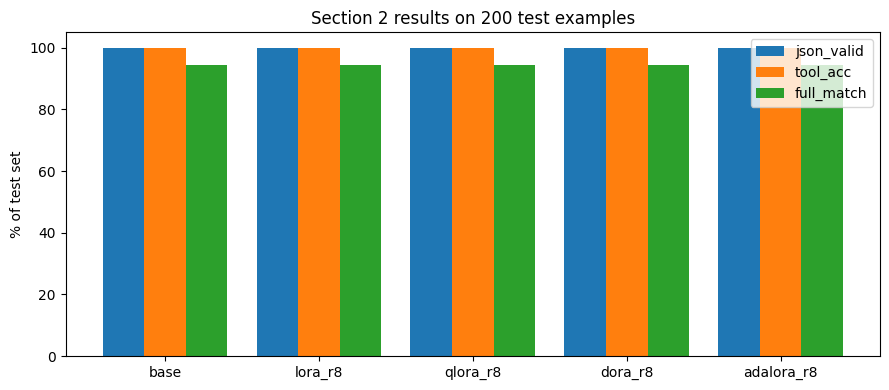

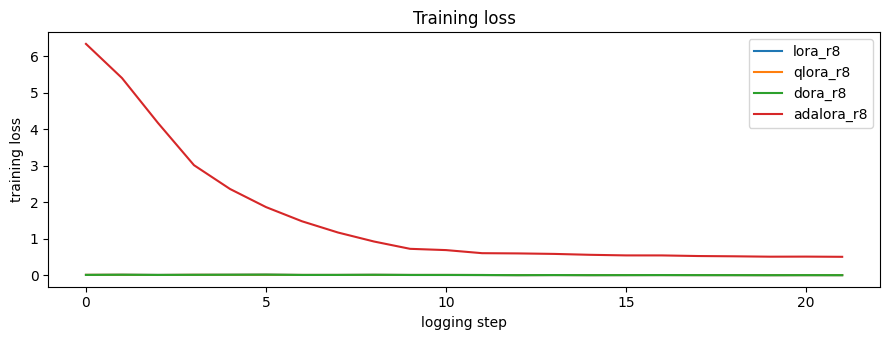

In [14]:
fig, ax = plt.subplots(figsize=(9, 4))
cols = ["json_valid_%", "tool_acc_%", "full_match_%"]
x = np.arange(len(results))
for i, c in enumerate(cols):
    ax.bar(x + (i - 1) * 0.27, results[c], width=0.27, label=c.replace("_%", ""))
ax.set_xticks(x)
ax.set_xticklabels(results["run"])
ax.set_ylabel("% of test set")
ax.set_ylim(0, 105)
ax.set_title(f"Section 2 results on {len(test_data)} test examples")
ax.legend()
plt.tight_layout()
plt.savefig(RESULTS_DIR / "section2_bars.png", dpi=150)
plt.show()

fig, ax = plt.subplots(figsize=(9, 3.5))
for name, t in all_train.items():
    if t and t["loss_history"]:
        ax.plot(t["loss_history"], label=name)
ax.set_xlabel("logging step")
ax.set_ylabel("training loss")
ax.set_title("Training loss")
ax.legend()
plt.tight_layout()
plt.savefig(RESULTS_DIR / "training_loss.png", dpi=150)
plt.show()

### What I see in Section 2

**All five rows have the same accuracy.** Every row, including the base model, got 200/200 valid JSON, 100% tool accuracy and 189/200 (94.5%) full match. No row had a hallucinated function name, extra text around the JSON, or a missing call.

I did not expect this. The question describes a model that adds explanations and invents function names, so I expected a weak base row. But with glaive's system prompt plus my one extra line ("reply with only a JSON object"), Qwen2.5-1.5B-Instruct already does the format perfectly on these 200 examples. The training loss agrees: LoRA's loss was already 0.0073 at the first log (step 10), so there was very little left to learn.

**Same score does not mean same outputs.** LoRA, QLoRA and DoRA each changed 11 to 12 of the 200 outputs compared to the base model. They all fixed the same 3 examples (#33, #85, #170) and broke the same 3 (#47, #148, #171), so the total stayed at 189. I look at why in the failure analysis.

**AdaLoRA changed nothing.** Its 200 outputs are identical to the base model's, character for character. The adapter was loaded (generation was slower, 104.7 vs 225.7 tok/s), and in my CPU test the same code did change outputs with an AdaLoRA adapter. My guess is that AdaLoRA's update stayed too small to flip any greedy token: its E vector starts at zero, and most of its logged loss (6.33 at the start, 0.50 at the end) is the orthogonality penalty, not the language model loss. I did not check the size of the trained weights, so this stays a guess.

AdaLoRA did move its rank budget. Starting from 12 everywhere, it ended with q_proj and o_proj at about 10.5 on average and the three MLP matrices at about 6.5, with almost no difference between early and late layers.

**So the methods only differ in cost:**

| | LoRA | QLoRA | DoRA | AdaLoRA |
|---|---|---|---|---|
| peak memory (GB) | 7.32 | 6.53 | 8.20 | 8.46 |
| training time (min) | 7.3 | 9.7 | 13.0 | 12.7 |
| unmerged speed (tok/s) | 109.2 | 81.0 | 58.8 | 104.7 |

**Hardware note.** All runs used the Colab GPU runtime with fp16, so every run used the same precision. QLoRA, DoRA, AdaLoRA and the rank sweep were trained in the final session. The base row and LoRA r = 8 were loaded from an earlier session, whose GPU the notebook does not show. LoRA r = 8 took 7.3 min, almost exactly what r = 4, 16 and 32 took in the final session (7.4 min), so it was very likely the same kind of GPU, but I can't prove it.

QLoRA saved only 0.8 GB compared to LoRA. The fp16 weights of a 1.54B model are only about 3.1 GB, so most of the memory goes to activations, not weights. Part of it is probably also that `prepare_model_for_kbit_training` casts the unquantized parts, like the 233M-parameter embedding, to fp32.

## Section 3: Is a bigger rank better?

I take the best method from Section 2 (highest full match, ties broken by tool accuracy) and train it again at r = 4, 16 and 32. The r = 8 run already exists, so I reuse it.

I keep **lora_alpha = 2 x r** for every rank. LoRA scales the update by alpha / r, so with alpha = 2r the scale stays at 2 for every rank. If I kept alpha fixed at 16, a bigger rank would also mean a smaller scale, and I wouldn't know which of the two changed the result.

In [15]:
finetuned = results[results["method"] != "base"]
best_row = finetuned.sort_values(["full_match_%", "tool_acc_%"], ascending=False).iloc[0]
BEST_METHOD = best_row["method"]
print("best method from Section 2:", BEST_METHOD,
      f"(full match {best_row['full_match_%']}%, tool acc {best_row['tool_acc_%']}%)")

rank_rows = []
for r in [4, 8, 16, 32]:
    name = f"{BEST_METHOD}_r{r}"
    print("=" * 20, name)
    t = train_run(name, BEST_METHOD, r)
    e = eval_run(name, BEST_METHOD)
    all_train[name], all_eval[name] = t, e
    rank_rows.append(results_row(name, BEST_METHOD, r))
rank_df = pd.DataFrame(rank_rows)
rank_df.to_csv(RESULTS_DIR / "results_rank_sweep.csv", index=False)
rank_df

best method from Section 2: lora (full match 94.5%, tool acc 100.0%)
==================== lora_r4


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

[lora_r4] trainable 4,616,192 of 1,548,330,496 (0.298%)


Step,Training Loss
10,0.006993
20,0.010032
30,0.006440
40,0.007277
50,0.009925
60,0.010952
70,0.005506
80,0.005966
90,0.008828
100,0.004582


[lora_r4] done in 7.4 min, peak memory 8.120330810546875 GB, final loss 0.001449822261929512


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

... (10 outputs left out)

[lora_r32] done in 7.4 min, peak memory 8.617395877838135 GB, final loss 0.001324381958693266


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

[lora_r32] json valid 200/200, tool acc 100.0%, full match 94.5%, 108.7 tok/s


,run,method,rank,trainable_params,trainable_%,peak_mem_GB,train_min,json_valid,json_valid_%,tool_acc_%,full_match_%,tok_per_s,hallucinated_names,extra_text,no_call
0,lora_r4,lora,4,4616192,0.298,8.12,7.4,200/200,100.0,100.0,94.5,110.8,0,0,0
1,lora_r8,lora,8,9232384,0.595,7.32,7.3,200/200,100.0,100.0,94.5,109.2,0,0,0
2,lora_r16,lora,16,18464768,1.182,8.33,7.4,200/200,100.0,100.0,94.5,108.7,0,0,0
3,lora_r32,lora,32,36929536,2.336,8.62,7.4,200/200,100.0,100.0,94.5,108.7,0,0,0


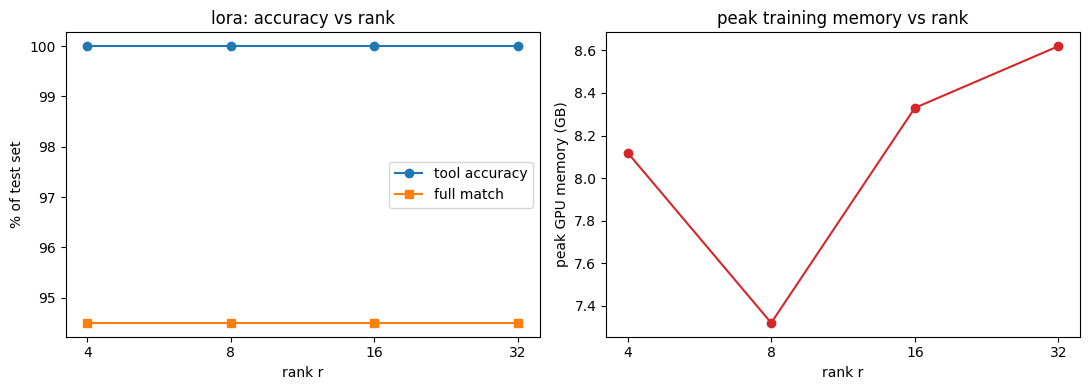

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ranks = rank_df["rank"].astype(int)
axes[0].plot(ranks, rank_df["tool_acc_%"], "o-", label="tool accuracy")
axes[0].plot(ranks, rank_df["full_match_%"], "s-", label="full match")
axes[0].set_xscale("log", base=2)
axes[0].set_xticks(ranks)
axes[0].set_xticklabels(ranks)
axes[0].set_xlabel("rank r")
axes[0].set_ylabel("% of test set")
axes[0].set_title(f"{BEST_METHOD}: accuracy vs rank")
axes[0].legend()
if rank_df["peak_mem_GB"].notna().any():
    axes[1].plot(ranks, rank_df["peak_mem_GB"], "o-", color="tab:red")
    axes[1].set_ylabel("peak GPU memory (GB)")
else:
    axes[1].text(0.5, 0.5, "no GPU in this run", ha="center", transform=axes[1].transAxes)
axes[1].set_xscale("log", base=2)
axes[1].set_xticks(ranks)
axes[1].set_xticklabels(ranks)
axes[1].set_xlabel("rank r")
axes[1].set_title("peak training memory vs rank")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "rank_sweep.png", dpi=150)
plt.show()

### Does doubling the rank buy anything?

All four methods tied in Section 2, so my rule (full match, then tool accuracy) picked the first row, LoRA. LoRA was also the fastest to train.

**No.** The left plot is two flat lines: 100% tool accuracy and 94.5% full match at r = 4, 8, 16 and 32. Going from r = 4 to r = 32 multiplied the trainable parameters by 8 (4,616,192 to 36,929,536), and accuracy did not move by a single example. Training time also stayed flat at 7.3 to 7.4 minutes.

Memory went up a little, from 8.12 GB at r = 4 to 8.62 GB at r = 32. The r = 8 point (7.32 GB) is lower than r = 4, which makes no sense from the rank alone. The r = 8 run was trained in an earlier Colab session and only loaded from Drive here, while r = 4, 16 and 32 were trained in the final session after several other runs, so the memory state on the GPU was probably different. I don't have a clean explanation, so I would not read anything into differences of less than about 1 GB here.

My conclusion from the graph: on this task r = 4 is enough, and a bigger rank only costs memory and adapter size. One caveat: the base model already got 94.5%, so this task had almost no headroom. This experiment cannot say whether rank matters on a harder task.

## Merge test

For LoRA, QLoRA and DoRA I measure inference speed with the adapter kept separate (unmerged) and after `merge_and_unload()`, on the first 50 test examples.

QLoRA needs extra care. Its base weights are 4 bit, so "merging" means: dequantize a weight to fp16, add the LoRA update, and quantize it back to 4 bit. That last rounding step can wipe out part of the small LoRA update. So for QLoRA I compare three versions: the unmerged 4-bit model, the merged-and-requantized 4-bit model, and the adapter merged into a plain fp16 copy of the base model.

In [17]:
N_MERGE = min(50, len(test_data))
merge_sub = test_data[:N_MERGE]

def quick_eval(model, label):
    outs, tps = generate_all(model, merge_sub)
    s = summarize([score_one(ex, o) for ex, o in zip(merge_sub, outs)])
    print(f"  {label}: tool acc {s['tool_correct_pct']:.1f}%, full match {s['full_match_pct']:.1f}%, {tps:.1f} tok/s")
    return {"setting": label, "tool_acc_%": s["tool_correct_pct"], "full_match_%": s["full_match_pct"],
            "json_valid_%": s["json_valid_pct"], "tok_per_s": tps}

def merge_test(name, method):
    f = run_dir(name) / "merge_test.json"
    if f.exists():
        return json.load(open(f))
    if method == "qlora" and LOCAL_CPU:
        return None
    print(name)
    rows = []
    free_memory()
    model = load_trained(name, method)
    rows.append(quick_eval(model, "unmerged"))
    model = model.merge_and_unload()
    rows.append(quick_eval(model, "merged into 4-bit" if method == "qlora" else "merged"))
    del model
    free_memory()
    if method == "qlora":
        # same adapter, but merged into an fp16 copy of the base model
        model = AutoModelForCausalLM.from_pretrained(MODEL_ID, dtype=torch.float16, device_map={"": 0})
        model = PeftModel.from_pretrained(model, str(run_dir(name) / "adapter")).merge_and_unload()
        rows.append(quick_eval(model, "merged into fp16 base"))
        del model
        free_memory()
    for row in rows:
        row["run"] = name
    with open(f, "w") as fh:
        json.dump(rows, fh, indent=1)
    return rows

merge_rows = []
for name, method in [("lora_r8", "lora"), ("qlora_r8", "qlora"), ("dora_r8", "dora")]:
    out = merge_test(name, method)
    if out:
        merge_rows += out
merge_df = pd.DataFrame(merge_rows)
if len(merge_df):
    merge_df = merge_df[["run", "setting", "tok_per_s", "tool_acc_%", "full_match_%", "json_valid_%"]].round(1)
merge_df.to_csv(RESULTS_DIR / "merge_test.csv", index=False)
merge_df

lora_r8


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

  unmerged: tool acc 100.0%, full match 96.0%, 92.2 tok/s
  merged: tool acc 100.0%, full match 96.0%, 187.2 tok/s
qlora_r8


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

  unmerged: tool acc 100.0%, full match 96.0%, 66.9 tok/s


/usr/local/lib/python3.13/dist-packages/peft/tuners/lora/bnb.py:377: UserWarning: Merge lora module to 4-bit linear may get different generations due to rounding errors.
  warnings.warn(


... (2 outputs left out)

  merged into fp16 base: tool acc 100.0%, full match 96.0%, 184.3 tok/s
dora_r8


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

  unmerged: tool acc 100.0%, full match 96.0%, 49.3 tok/s
  merged: tool acc 100.0%, full match 96.0%, 187.3 tok/s


,run,setting,tok_per_s,tool_acc_%,full_match_%,json_valid_%
0,lora_r8,unmerged,92.2,100.0,96.0,100.0
1,lora_r8,merged,187.2,100.0,96.0,100.0
2,qlora_r8,unmerged,66.9,100.0,96.0,100.0
3,qlora_r8,merged into 4-bit,114.2,100.0,90.0,100.0
4,qlora_r8,merged into fp16 base,184.3,100.0,96.0,100.0
5,dora_r8,unmerged,49.3,100.0,96.0,100.0
6,dora_r8,merged,187.3,100.0,96.0,100.0


### What merging did

All numbers here are on the first 50 test examples, so the speeds are not directly comparable to the 200-example table above.

- **LoRA:** merging doubled the speed (92.2 to 187.2 tok/s), with full match unchanged at 96.0%.
- **DoRA:** the biggest gain, 49.3 to 187.3 tok/s (3.8x), again with no accuracy change. Unmerged DoRA is the slowest setting I measured, because it recomputes the weight norm on every forward pass. Once merged, that cost disappears and it runs at the same speed as merged LoRA.
- **QLoRA:** merging back into 4-bit weights is the one setting that lost accuracy. Full match dropped from 96.0% to 90.0%, which is 3 of the 50 examples. The merged weight has to be rounded back to NF4, and that rounding destroys part of the small LoRA update. peft warns about exactly this in the output above ("may get different generations due to rounding errors"). It also only reached 114.2 tok/s, because 4-bit layers still dequantize on every pass. Merging the same QLoRA adapter into a plain fp16 copy of the base model kept 96.0% and ran at 184.3 tok/s. So QLoRA is cheap to train, but to serve it well you have to go back to an fp16 base anyway.

## Failure analysis

I take the best r = 8 model from Section 2 and look at test examples it still gets wrong (not a full match). I label each one automatically first, then check the labels by eye:

- **broken JSON**: there is a `{` but nothing parses
- **refused to call a tool**: no JSON at all, just text
- **wrong tool**: a real function from the list, but the wrong one (or a made-up function name)
- **made-up argument**: right function, but an argument key that is not in the correct call
- **other**: right function and keys, but a wrong value, or a missing argument

In [18]:
def failure_label(p):
    if p["pred_name"] is None:
        return "broken JSON" if "{" in p["output"] else "refused to call a tool"
    if not p["tool_correct"]:
        return "wrong tool (made-up name)" if p["hallucinated_name"] else "wrong tool"
    gold_keys = set(p["gold"]["arguments"])
    pred_keys = set(p["pred_args"]) if isinstance(p["pred_args"], dict) else set()
    if pred_keys - gold_keys:
        return "made-up argument"
    if gold_keys - pred_keys:
        return "other (missing argument)"
    return "other (wrong argument value)"

BEST_NAME = f"{BEST_METHOD}_r8"
preds = [json.loads(l) for l in open(run_dir(BEST_NAME) / "predictions.jsonl")]
wrong = [p for p in preds if not p["full_match"]]
for p in wrong:
    p["label"] = failure_label(p)
print(f"{BEST_NAME}: {len(wrong)} of {len(preds)} test examples are not a full match")
print(pd.Series([p["label"] for p in wrong]).value_counts().to_string())

# pick up to 5, trying to cover different labels first
picked, seen = [], set()
for p in wrong:
    if p["label"] not in seen:
        picked.append(p)
        seen.add(p["label"])
for p in wrong:
    if len(picked) >= 5:
        break
    if p not in picked:
        picked.append(p)
picked = picked[:5]

for i, p in enumerate(picked, 1):
    print(f"\n--- Failure {i}: {p['label']}")
    print("Customer:", p["user"])
    print("Correct :", json.dumps(p["gold"]))
    print("Model   :", p["output"])
with open(RESULTS_DIR / "failure_examples.json", "w") as f:
    json.dump({"run": BEST_NAME, "n_wrong": len(wrong),
               "label_counts": pd.Series([p["label"] for p in wrong]).value_counts().to_dict(),
               "examples": picked}, f, indent=1)

lora_r8: 11 of 200 test examples are not a full match
other (wrong argument value)    7
made-up argument                4

--- Failure 1: other (wrong argument value)
Customer: Can you find me some news articles about the Mars Rover from the last week?
Correct : {"name": "search_news", "arguments": {"keywords": ["Mars Rover"], "date_range": {"start_date": "2022-02-01", "end_date": "2022-02-08"}}}
Model   : {"name": "search_news", "arguments": {"keywords": ["Mars Rover"], "date_range": {"start_date": "2022-03-15", "end_date": "2022-03-21"}}}

--- Failure 2: made-up argument
Customer: I am looking for a book but I can't remember the title. The author's name is George Orwell and it's a dystopian novel.
Correct : {"name": "search_books", "arguments": {"author": "George Orwell", "genre": "dystopian", "max_results": 5}}
Model   : {"name": "search_books", "arguments": {"query": "", "author": "George Orwell", "genre": "dystopian", "max_results": 5}}

--- Failure 3: other (wrong argument value)

### Pattern in the failures

I checked each automatic label by hand against that example's function schema:

1. **Mars Rover news:** other. "The last week" has no reference date in the prompt, so the gold dates (2022-02-01 to 2022-02-08) can't be worked out from the message. The model's dates are as good a guess as the gold ones.
2. **George Orwell book:** made-up argument. `query` is a real optional field, but the model filled it with an empty string the user never asked for.
3. **New York hotel:** other. The model rewrote "1st May" as "2022-05-01" and invented the year.
4. **Calorie tracking:** other. It wrote `"meal": "lunch"` where the gold has `"Lunch - Cheeseburger with fries"`; the base model gave the same answer.
5. **Italian restaurant:** made-up argument. `location` is not in the schema at all.

**The pattern:** all 11 wrong answers out of 200 have the right tool and valid JSON. Every mistake is in the argument values, and they fall into three groups:
- relative dates with no "today" in the prompt (3)
- empty or invented query fields (5)
- value conventions (3), such as `rate: 5` where the gold expects `0.05`, or "French" where the gold has "fr"

Several gold answers are themselves arbitrary. Example #33 expects the hotel dates as "2022-05-01", while example #47, the same kind of request, expects "1st May". Fine-tuning taught the model the ISO habit, which fixed #33 and broke #47. That is exactly why the score stayed at 189.

## Small e-commerce demo

Now the actual use case from the question. I define the startup's four functions as JSON schemas in the same format as glaive, and try the best model on 8 messages I wrote myself. The important ones are the delivery date questions: they should go to `check_order_status` or `track_shipment`, and must **not** trigger `initiate_refund`.

In [19]:
SHOP_FUNCTIONS = [
    {"name": "check_order_status",
     "description": "Get the current status of a customer's order",
     "parameters": {"type": "object", "properties": {
         "order_id": {"type": "string", "description": "The order ID, if the customer gives one"},
         "order_date": {"type": "string", "description": "When the order was placed, if no order ID is given"}},
         "required": []}},
    {"name": "initiate_refund",
     "description": "Start a refund for an order. Only use when the customer asks for their money back",
     "parameters": {"type": "object", "properties": {
         "order_id": {"type": "string", "description": "The order ID to refund"},
         "reason": {"type": "string", "description": "Why the customer wants a refund"}},
         "required": ["order_id", "reason"]}},
    {"name": "track_shipment",
     "description": "Track a shipment and get the expected delivery date",
     "parameters": {"type": "object", "properties": {
         "tracking_number": {"type": "string", "description": "The courier tracking number"}},
         "required": ["tracking_number"]}},
    {"name": "escalate_to_human",
     "description": "Hand the conversation to a human support agent",
     "parameters": {"type": "object", "properties": {
         "reason": {"type": "string", "description": "Short reason for the escalation"},
         "priority": {"type": "string", "enum": ["low", "medium", "high"], "description": "How urgent it is"}},
         "required": ["reason"]}},
]
shop_system = ("You are a helpful assistant with access to the following functions. Use them if required -\n"
               + "\n\n".join(json.dumps(f, indent=4) for f in SHOP_FUNCTIONS))
shop_names = [f["name"] for f in SHOP_FUNCTIONS]

DEMO = [
    ("Where is my order? I placed it last Tuesday", "check_order_status"),
    ("When will my package arrive? The tracking number is TRK784512.", "track_shipment"),
    ("What is the expected delivery date for order 45821?", "check_order_status"),
    ("Can you check the status of order 10293 please?", "check_order_status"),
    ("The blender in order 99812 arrived broken. I want my money back.", "initiate_refund"),
    ("Please refund order 77341, the shoes were the wrong size.", "initiate_refund"),
    ("My parcel PK55120LHR has not moved in 5 days, where is it?", "track_shipment"),
    ("This is the third time I am writing to you. I want to talk to a real person now.", "escalate_to_human"),
]
demo_examples = [{"system": shop_system, "user": m, "func_names": shop_names,
                  "call": {"name": want, "arguments": {}}} for m, want in DEMO]

free_memory()
demo_model = load_trained(BEST_NAME, BEST_METHOD)
demo_outs, _ = generate_all(demo_model, demo_examples)
del demo_model
free_memory()

demo_rows = []
for (msg, want), out in zip(DEMO, demo_outs):
    sc = score_one({"call": {"name": want, "arguments": {}}, "func_names": shop_names}, out)
    demo_rows.append({"message": msg, "expected_tool": want, "model_output": out,
                      "valid_json": sc["json_valid"], "right_tool": sc["tool_correct"],
                      "refund_by_mistake": sc["pred_name"] == "initiate_refund" and want != "initiate_refund"})
demo_df = pd.DataFrame(demo_rows)
demo_df.to_csv(RESULTS_DIR / "demo_outputs.csv", index=False)
print(f"right tool: {demo_df['right_tool'].sum()}/{len(demo_df)}, valid JSON: {demo_df['valid_json'].sum()}/{len(demo_df)}, "
      f"refunds by mistake: {demo_df['refund_by_mistake'].sum()}")
pd.set_option("display.max_colwidth", 120)
demo_df

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

right tool: 7/8, valid JSON: 8/8, refunds by mistake: 0


,message,expected_tool,model_output,valid_json,right_tool,refund_by_mistake
0,Where is my order? I placed it last Tuesday,check_order_status,"{""name"": ""check_order_status"", ""arguments"": {""order_date"": ""last Tuesday""}}",True,True,False
1,When will my package arrive? The tracking number is TRK784512.,track_shipment,"{""name"": ""track_shipment"", ""arguments"": {""tracking_number"": ""TRK784512""}}",True,True,False
2,What is the expected delivery date for order 45821?,check_order_status,"{""name"": ""track_shipment"", ""arguments"": {""tracking_number"": ""45821""}}",True,False,False
3,Can you check the status of order 10293 please?,check_order_status,"{""name"": ""check_order_status"", ""arguments"": {""order_id"": ""10293""}}",True,True,False
4,The blender in order 99812 arrived broken. I want my money back.,initiate_refund,"{""name"": ""initiate_refund"", ""arguments"": {""order_id"": ""99812"", ""reason"": ""broken""}}",True,True,False
5,"Please refund order 77341, the shoes were the wrong size.",initiate_refund,"{""name"": ""initiate_refund"", ""arguments"": {""order_id"": ""77341"", ""reason"": ""wrong size""}}",True,True,False
6,"My parcel PK55120LHR has not moved in 5 days, where is it?",track_shipment,"{""name"": ""track_shipment"", ""arguments"": {""tracking_number"": ""PK55120LHR""}}",True,True,False
7,This is the third time I am writing to you. I want to talk to a real person now.,escalate_to_human,"{""name"": ""escalate_to_human"", ""arguments"": {""reason"": ""Customer needs immediate attention due to repeated issues."", ...",True,True,False


### Comment on the demo

The model gave valid JSON for all 8 messages, picked the tool I expected for 7, and never started a refund by mistake. For "Where is my order? I placed it last Tuesday" it called `check_order_status` with `order_date: "last Tuesday"` and did not invent an order ID. The one miss was "expected delivery date for order 45821": it called `track_shipment` with the order number as the tracking number. That is still not a refund, but it is a made-up argument, and my own description for `track_shipment` ("get the expected delivery date") probably pulled it there.

In [20]:
# zip everything so it can be downloaded in one go (adapters included)
zip_path = shutil.make_archive(str(BASE_DIR.parent / ("q2_results_smoke" if SMOKE_TEST else "q2_results")), "zip", RESULTS_DIR)
print("zipped to", zip_path, f"({os.path.getsize(zip_path) / 1024**2:.1f} MB)")
if IN_COLAB:
    from google.colab import files
    files.download(zip_path)

zipped to /content/drive/MyDrive/q2_results.zip (675.4 MB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>